# Finite Difference Methods

Finite Difference Methods (FDM) are one of the popular numerical methods used in computational finance. FDM are discretizations used for solving differential equations by approximating them with difference equations. It is one of the simplest and the oldest methods to solve differential equations. These techniques were applied to numerical applications as early as 1950s.

FDM are similar in approach to the (binomial) tress. However, instead of discretizing asset prices and the passage of time in a tree structure, it discretizes in a grid - with time and price steps - by calculating the value at every possible grid points.

Explicit, Implicit and Crank-Nicolson are the three popular approaches of FDM. The explicit methods are simple to implement, but it does not always converge and largely depends on the size of the time and asset step. Explicit methods are unstable when compared to other two methods. Finite Difference approach is peferred for low dimensional problem, usually upto 4 dimensions.

## Differentiation Using The Grid

he Binomial method contains the diffusion - the volatility - in the tree structure whereas in FDM, the 'tree' is fixed and we change the parameters to reflect the changing diffusion. We will now define the grid by specifying the time step δt
and asset step δs and discretize S and time to maturity t as 

 $$ S = i\delta{s}$$
 $$ t = T -k\delta{t}$$
 
where 0 ≤i ≤ I and 0 ≤k ≤ K

Here i and k are respective steps in the grid and we can write the value of the option at each grid points as
 $$ V_i^k = (i\delta{s} ,T -k\delta{t}) $$

## Approximating Greeks

The greeks terms, the Black–Scholes equation can be written as

 $$ \Theta + \frac{1}{2} \sigma^2 S^2 \Gamma + r S \Delta -rV =0  $$
 
 Assume that we know the option value at each grid points, we can extract the derivatives of the option using Taylor series expansion
 
**Approxinating** $\Theta $ <br>
We know that the first derivative of option as,
$$ \frac{\partial{V}}{\partial{t}} = \lim_{h\to0} \frac{V(S, t+h) - V(S,t)}{h} $$
 
We can then approximate the time derivative from our grid using

$$ \frac{\partial{V}}{\partial{t}}(S,t) \approx  \frac{V_i^k - V_i^{k+1}}{\partial{t}} $$

**Approxinating** $\Delta $ <br>
From the lecture, we know that the central difference has much lower error when compared to forward and backward differences. Accordingly, we can approximate the first derivative of option with respect to the underlying as
$$ \frac{\partial{V}}{\partial{t}}(S,t) \approx  \frac{V_{i+1}^k - V_{i-1}^k}{2\delta{s}} $$

**Approxinating** $\Gamma $ <br>
From the lecture, we know that the central difference has much lower error when compared to forward and backward differences. Accordingly, we can approximate the first derivative of option with respect to the underlying as
$$ \frac{\partial{V}}{\partial{t}}(S,t) \approx  \frac{V_{i+1}^k + V_{i-1}^k - 2V_{i}^k}{\delta{s^2}} $$

#### Import Libraries

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# to reload another python script 
from importlib import reload

# data visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# tabke formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

path_dir = 'C:/Admin/CQF Course/Python Labs/Finite Difference Methods'

In [2]:
# Set max row and columns to 50
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 50)
pd.options.display.float_format = '{:0.2f}'.format 

### Example

Suppose that we know the value of the option on the below grid points, we can then easily evaluate the greeks as follows

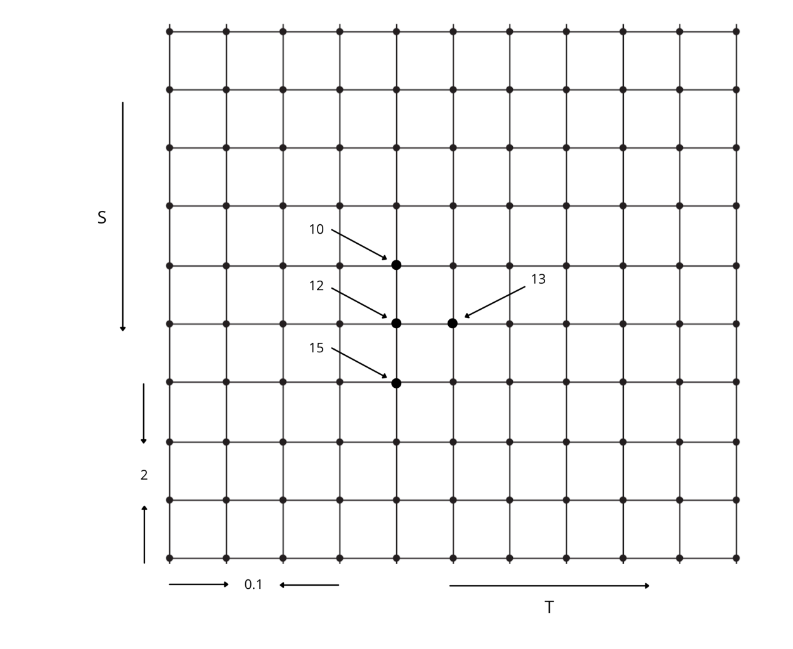

In [3]:
Image.open(os.path.join(path_dir,'FDM_1.png'))

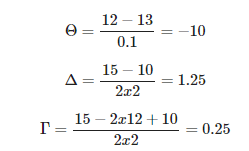

In [4]:
Image.open(os.path.join(path_dir,'FDM_2.png'))

## FDM Option Pricing Techniques

As with other option pricing techniques Explicit Finite Difference methods are used to price options using what is essentially a three step process.

Step 1: Generate the grid by specifying grid points.<br>
Step 2: Specify the final or initial conditions.<br>
Step 3: Use boundary conditions to calculate option values and step back down the grid to fill it.

**European Option**

To price an option, we generate a finite grid of a specified asset and time steps for a given maturity. Next, we specify the initial and boundary conditions to calculate payoff when S and T equals zero. We then step back to fill the grid with newer values derived from the earlier values.

In [5]:
# Specify parameters
T = 1                        # time to maturity
E = 100                      # strike price
r = 0.05                     # risk-free rate
vol = 0.2                    # volatility
flag = 1                     # flag = 1 for call, -1 for puts

NAS = 20                     # number of asset steps
ds = 2*E/NAS                 # asset price step


dt = 0.9/(vol**2)/(NAS**2)   # time step,for stability issue
NTS  = int(T / dt) + 1       # number of time steps
dt = T/NTS 

### Generate Grid

**Grid is very similar to Binomial Tree** 
- here we are looping on first k(columns,time step on X axis) and then on i(rows, asset step on Y axis)
- in Binomial, we are looping on first j(columns, time step on X axis) and then on i(rows)
- logic is exactly similar what we did in Lecture, here we are deriving values from greeks 

In [6]:
# Create asset price steps i*ds
s = np.arange(0,(NAS+1)*ds,ds)

# # Create time steps T - k*dt
t = T - np.arange((NTS)*dt,-dt,-dt)

# Initialize the grid with zeros
grid = np.zeros((len(s),len(t)))

# Subsume the grid points into a dataframe
# with asset price as index and time steps as columns
grid = pd.DataFrame(data = grid,index = s,columns = np.around(t,3))

In [7]:
grid

,0.00,0.06,0.11,0.17,0.22,0.28,0.33,0.39,0.44,0.50,0.56,0.61,0.67,0.72,0.78,0.83,0.89,0.94,1.00
0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
10.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
20.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
30.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
40.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
60.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
70.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
80.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
90.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### Specify Condition

Specify final condition and payoffs

$$ V_i^0 =   max(i\delta{s} -E,0) $$

In [8]:
if flag ==1:
    grid.iloc[:,0] = np.maximum(s-E,0)
else:
    grid.iloc[:,0] = np.maximum(E-s,0)

### Fill the Grid

Specify boundary condition at S = 0
$$ V_0^{k+1} =   (1-r\delta{t})V_0^k $$

Specify boundary condition at S = ∞
$$ V_{I+1}^{k} =  2V_I^k - V_{I-1}^k $$

In [9]:
for k in range(1,len(t)):
    for i in range(1,len(s)-1):
        
        # Set boundary condition at S = 0
        grid.iloc[0,k] = (1-r*dt)*grid.iloc[0,k-1]
        
        delta = (grid.iloc[i+1,k-1] - grid.iloc[i-1,k-1])/(2*ds)
        gamma = (grid.iloc[i+1,k-1]-2*grid.iloc[i,k-1]+grid.iloc[i-1,k-1]) / (ds**2)
        theta = (-0.5* vol**2 * s[i]**2 * gamma) - (r*s[i]*delta) + (r*grid.iloc[i,k-1])
        
        grid.iloc[i,k] = grid.iloc[i,k-1] - (theta*dt)
        
        # Set boundary condition at S = infinity  # gamma = 0, so you can linearly extract
        grid.iloc[len(s)-1,k] = 2* grid.iloc[len(s)-2,k] - grid.iloc[len(s)-3,k]

### Visualize the payoff

In [10]:
grid.iplot(kind = 'surface')                           # df.ilpot(kind = 'surface')

### Bilinear Interpolation

We have generated the grid and filled it with the possible option values. However, if we have to estimate option value or its derivatives on the mesh points, how can we estimate the value at points in between? The simplest way is to do a two-dimensional interpolation method called Bilinear Interpolation.

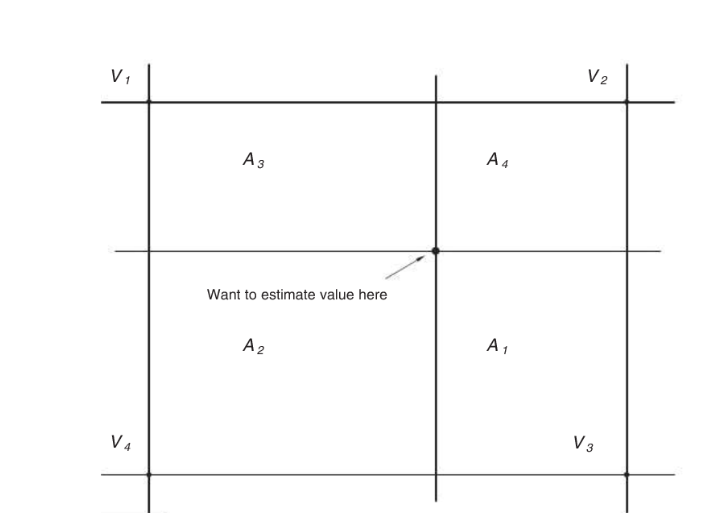

In [11]:
Image.open(os.path.join(path_dir,'FDM_3.png'))

The option value can be estimated using the values from the nearest neighbouring values. Assume 
V1,V2,V3 and V4 are the option values from the nearest neighbour and 
A1,A2,A3 and A4 are the areas of the rectanges made by the four corners and the interior points, we can approximate the option value at the interior points as

$$ \frac{\sum_{i=1}^{4} A_iV_i}{\sum_{i=1}^{4}A_i} $$

In [12]:
def bilinear_interpolation(asset_price,time_to_maturity,df):
    row_l = grid.index[grid.index < asset_price ][-1]
    row_u = grid.index[grid.index >= asset_price ][0]
    col_l = grid.columns[grid.columns < time_to_maturity ][-1]
    col_u = grid.columns[grid.columns >= time_to_maturity ][0]
    
    a1 = (time_to_maturity -col_l)*(asset_price -row_l)
    a2 = (col_u-time_to_maturity)*(asset_price - row_l)
    a3 = (time_to_maturity -col_l)*(row_u-asset_price)
    a4 = (col_u-time_to_maturity)*(row_u-asset_price)
    
    v1 = grid.loc[row_l,col_l]
    v2 = grid.loc[row_l,col_u]
    v3 = grid.loc[row_u,col_l]
    v4 = grid.loc[row_u,col_u]
    
    V = np.array([v1,v2,v3,v4])
    A = np.array([a1,a2,a3,a4])
    
    return (A@V)/(np.sum(A)) 

In [13]:
# Option value, approximated
bilinear_interpolation(105,0.3,grid)

8.582379421620987

In [14]:
def fdm_option(strike,rate, time_to_maturity,volatility, NAS,flag):
    
    E = strike
    T = time_to_maturity
    
    ds = 2*E/NAS                 
    dt = 0.9/(volatility**2)/(NAS**2)   
    NTS  = int(T / dt) + 1       
    dt = T/NTS 
    

    s = np.arange(0,(NAS+1)*ds,ds)
    t = T - np.arange((NTS)*dt,-dt,-dt)

    grid = np.zeros((len(s),len(t)))
    grid = pd.DataFrame(data = grid,index = s,columns = np.around(t,3))
    
    if flag ==1:
        grid.iloc[:,0] = np.maximum(s-E,0)
    else:
        grid.iloc[:,0] = np.maximum(E-s,0)
        
    for k in range(1,len(t)):
        for i in range(1,len(s)-1):
            
            # Set boundary condition at S = 0
            grid.iloc[0,k] = (1-r*dt)*grid.iloc[0,k-1]

            delta = (grid.iloc[i+1,k-1] - grid.iloc[i-1,k-1])/(2*ds)
            gamma = (grid.iloc[i+1,k-1]-2*grid.iloc[i,k-1]+grid.iloc[i-1,k-1]) / (ds**2)
            theta = (-0.5* vol**2 * s[i]**2 * gamma) - (r*s[i]*delta) + (r*grid.iloc[i,k-1])

            grid.iloc[i,k] = grid.iloc[i,k-1] - (theta*dt)

            # Set boundary condition at S = infinity  # gamma = 0, so you can linearly extract
            grid.iloc[len(s)-1,k] = 2* grid.iloc[len(s)-2,k] - grid.iloc[len(s)-3,k]
            
    return np.around(grid,2)


## Convergence Analysis

In [15]:
# Iterate over asset steps (NAS)
NAS_list = [10,20,30,40,50,60]
list_fdm_option = []

for i in NAS_list:
    list_fdm_option.append(fdm_option(100,0.05,1,0.2,i,1).loc[100,1])


# black scholes pricing
import bsm
reload(bsm)

bsm_option = bsm.BlackScholes(100,100,0.05,1,0.2)
call_bsm_option = round(bsm_option.call_price,2)
call_bsm_option = call_bsm_option.repeat(len(NAS_list))


df = pd.DataFrame(list(zip(list_fdm_option,call_bsm_option)),columns=['FDM', 'BS'], index=NAS_list)

## References

[Python Resources](https://github.com/kannansingaravelu/PythonResources)